## This notebook demonstrates and compares multiple model optimization techniques for efficient CPU inference.
### Use this version:torch==2.10.0 torchvision==0.25.0 torchao==0.16.0 for this notebook**

### Quantization Techniques
- **Static Post-Training Quantization (PTQ)** using `X86InductorQuantizer()`
- **Quantization-Aware Training (QAT)** using `X86InductorQuantizer()`

Both quantization approaches are designed to reduce model size and improve inference efficiency while maintaining classification accuracy.

### Compilation Techniques
- **JIT (Just-In-Time) Compilation**: Compiles the model during runtime, providing optimization benefits with an initial compilation overhead.
- **AOTInductor (Ahead-of-Time Compilation)**: Compiles the model before deployment, eliminating runtime compilation overhead and enabling faster inference execution on CPU.

### Performance Evaluation
This notebook evaluates and compares:
- **Model accuracy**
- **Inference latency**
- **Model size**
- **Deployment efficiency**

for the following model variants:
- FP32 (floating-point baseline and best-performing candidate model)
- Static PTQ model
- QAT model
- JIT-compiled model
- AOTInductor-compiled model

The objective is to identify the best trade-off between accuracy, model size, and inference speed for CPU deployment.

### Getting Started

Before running this notebook, clone the repository containing all experiment files and dependencies. If you are using VS Code, install `ipykernel` and add the project's root directory to `sys.path` to ensure all local modules and utilities can be imported correctly throughout the notebook.

In [1]:
!git clone https://github.com/zarniminnnyan/resnet18_cifar10_experiments.git

Cloning into 'resnet18_cifar10_experiments'...
remote: Enumerating objects: 394, done.
remote: Counting objects: 100% (65/65), done.
remote: Compressing objects: 100% (44/44), done.
remote: Total 394 (delta 27), reused 41 (delta 19), pack-reused 329 (from 1)
Receiving objects: 100% (394/394), 66.19 MiB | 39.45 MiB/s, done.
Resolving deltas: 100% (180/180), done.


In [2]:
cd /kaggle/working/resnet18_cifar10_experiments


/kaggle/working/resnet18_cifar10_experiments


In [3]:
pip install lightning pytorch_lightning

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.0/45.0 kB 722.6 kB/s eta 0:00:00 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 849.3/849.3 kB 6.4 MB/s eta 0:00:00a 0:00:01
Note: you may need to restart the kernel to use updated packages.


In [4]:
!pip install torch==2.10.0 torchvision==0.25.0 torchao==0.16.0

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 14.1 MB/s eta 0:00:0000:0100:01
  Attempting uninstall: torchao
    Found existing installation: torchao 0.10.0
    Uninstalling torchao-0.10.0:
      Successfully uninstalled torchao-0.10.0


In [5]:
import torch 
import torchao 
print(torch.__version__)
print(torchao.__version__)

2.10.0+cu128
0.16.0


## Load Data

In [6]:
from utils.helper_utils import (
    load_prepare_cifar10,
    build_transforms
    )


from src.test import load_model_for_test,test_model
from utils.helper_utils import build_dataloader,measure_inference_mb_ms
from config.exp_config import dataset_dir,baseline_model_dir,csv_file_path
from torch.utils.data import DataLoader
from typing import List
from copy import deepcopy
import torch
import torch.nn as nn

In [7]:
#Device
device=torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

cuda


In [8]:
def get_datasets(add_standard_augmentation:bool,add_random_erasing:bool):
        #download cifar10 dataset if it doesn't exist or it is corrupted
        train_dataset,val_dataset,test_dataset=load_prepare_cifar10(
                dataset_path=f"{dataset_dir}", #notice i have chaged the dataset dir due to current script running jupyter notebook dir
                build_transforms=build_transforms,
                image_size=224,
                standard_aug=add_standard_augmentation,#set False not to be applied standard augmentation or True
                add_random_erasing=add_random_erasing
                )
        return train_dataset,val_dataset,test_dataset 

# Get dataset (Applied standard augmentation,Add random erasing)

In [9]:
train_dataset,val_dataset,test_dataset=get_datasets(add_standard_augmentation=True,add_random_erasing=True)

downloaded cifar10 dataset ...


## Prepare the data

# Prepare DataLoader with Cutmix/Mixup Application

In [152]:
train_loader,val_loader,test_loader=build_dataloader(
    batch_size=128,
    num_workers=4,
    use_cutmix_mixup=True,
    device=device,
    train_dataset=train_dataset,
    val_dataset=val_dataset,
    test_dataset=test_dataset
    )


## Load exp5 version 3.0 best candidate model

In [11]:
original_exp5_v3_model=load_model_for_test(
    is_baseline=False,
    model_dir="/kaggle/input/datasets/zarniminnnyan/exp5-v3", #Note : This should be the directory where you stored the model before the subfolder
    experiment_name="exp5_v3", #Note: This is specific subfolder for the model name. (eg. model_dir/exp5_v3/{experiment_name}_weight.ckpt )
    num_classes=10,
    device=device
    )

change the head of resnet18 to 10
--- Extracting Configurations ---
Extracted learning rates from training: [5.8843356115025935e-05, 8.791036923815453e-05, 0.000872719723562627]
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 211MB/s]
/usr/local/lib/python3.12/dist-packages/pytorch_lightning/utilities/migration/utils.py:56: The loaded checkpoint was produced with Lightning v2.6.6, which is newer than your current Lightning version: v2.6.5


In [12]:
f32_model_history=test_model(
    model=original_exp5_v3_model,
    test_dataloader=test_loader,
    num_classes=10,
    device=device,
    test_result_dir="./f32_model_history" #This is where you will store the f32 model history
        )

test model is in progress:   0%|          | 0/79 [00:00<?, ?it/s]

In [13]:
print(f"F32 best candidate model (Exp5 v 3.0) from experiments test accuracy: {f32_model_history["test_acc"]}%")

F32 best candidate model (Exp5 v 3.0) from experiments test accuracy: 94.31%


In [14]:
# Original Experiment 5 version 3.0 (F32 model)inference time and size on CPU

results=measure_inference_mb_ms(model=original_exp5_v3_model.model,input_shape=(1,3,224,224),save_path="./original_v3_inference",is_production=False,experiment_name="exp5_v3",device=torch.device("cpu"))
print(f"Exp 5 V 3.0 size and inference time before Quantization: {results}")

Average latency: 33.825 ms
State dict size: 44.80 MB
Exp 5 V 3.0 size and inference time before Quantization: {'model_time_ms': 33.82472709999661, 'state_dict_size_mb': 44.803531, 'exported_file_size_mb': None}


In [50]:
# model for static quantization
static_model_to_quantize=deepcopy(original_exp5_v3_model.model)
# model for qat quantization 
qat_model_to_quantize=deepcopy(original_exp5_v3_model.model)
#original_model 
original_model_=deepcopy(original_exp5_v3_model.model)

## Static PTQ Quantization 

## Export model for Quantization-ready

In [16]:
import torch
import torchvision.models as models
import copy
from torchao.quantization.pt2e.quantize_pt2e import prepare_pt2e, convert_pt2e
from torchao.quantization.pt2e import move_exported_model_to_train,move_exported_model_to_eval
import torchao.quantization.pt2e.quantizer.x86_inductor_quantizer as xiq
from torchao.quantization.pt2e.quantizer.x86_inductor_quantizer import X86InductorQuantizer
from torch.export import export
from torch.export.dynamic_shapes import Dim


def export_model(model):
    # Set the model to eval mode (you don't need to reset to eval mode at the calibration step)
    try:
        model.eval()
    except NotImplementedError:
        move_exported_model_to_eval(model)
        

    # Define the first dimension (batch size) as dynamic
    batch_dim = Dim("batch")
    dynamic_shapes = {"x": {0: batch_dim}}
    
    
    # Create the data, using the dummy data here as an example
    traced_bs =128
    # Random input tensor in channels-last format (NHWC), optimized for convs on GPU and supported on CPU
    x = torch.randn(traced_bs, 3, 224, 224).contiguous(memory_format=torch.channels_last)
    example_inputs = (x,)
    
    # Capture the FX Graph to be quantized
    with torch.no_grad():
        # Note: requires torch >= 2.6 (using export is recomended in pytorch document)
        exported_model = export(
            model,
            args=example_inputs,
            dynamic_shapes=dynamic_shapes,
            strict=True
        )
    return exported_model


## Apply configuration for Quantization targeting CPU (x86)

In [17]:
quantizer = X86InductorQuantizer()
quantizer.set_global(xiq.get_default_x86_inductor_quantization_config())

In [18]:
#exported model for static PTQ 
exported_model=export_model(static_model_to_quantize)

In [19]:
# prepare the model for Quantization-ready (Fuse BatchNorm + Conv2d and insert obversers at the appropriate places)
prepared_model = prepare_pt2e(exported_model.module(), quantizer)

## Calibrate for Post-Training Quantization

In [20]:


# define the dataset to calibrate
def calibrate(model:nn.Module, data_loader:torch.utils.data.DataLoader,requested_batches:int,device:torch.device):
    import tqdm.auto as tqdm

    
    model=move_exported_model_to_eval(model) #move to eval model before calibration (important for compile)
    total_batches=len(data_loader) 
    requested_loader_batches=min(requested_batches,total_batches)
    model.to(device)
    with torch.no_grad():
        for idx,(image,_) in enumerate(tqdm.tqdm(data_loader)):
            # for compatability with the torch.export 
            image = image.contiguous(memory_format=torch.channels_last).to(device)
            model(image)
            if idx+1>= requested_loader_batches: 
                print(f"Requested {requested_loader_batches} batches has reached")
                break 
        print(f"Calibration has finished after processing {requested_loader_batches} out of {total_batches}")
    return model

In [21]:
#calibrate for static PTQ
calibrated_model=calibrate(prepared_model,val_loader,50,device) 
#convert to pt2e quantized model
quantized_model = convert_pt2e(calibrated_model)

  0%|          | 0/79 [00:00<?, ?it/s]

Requested 50 batches has reached
Calibration has finished after processing 50 out of 79


# Move back to CPU for Quantization target

In [125]:
#moved quantized model back to CPU for CPU inference target 
quantized_model=quantized_model.to("cpu")

# Check the reliablity of Quantization helper functions

In [24]:
def check_if_quantized(quantized_model):
    
    conv_nodes = [n for n in quantized_model.graph.nodes if n.op == "call_function" and "conv2d" in str(n.target)]
    linear_nodes = [n for n in quantized_model.graph.nodes if n.op == "call_function" and "linear" in str(n.target)]
    
    def has_dq_input(node):
        return any("dequantize" in str(a.target) for a in node.args if hasattr(a, "target"))

    q_conv = sum(1 for n in conv_nodes if has_dq_input(n))
    q_linear = sum(1 for n in linear_nodes if has_dq_input(n))
    
    print(f"Conv2d:  {q_conv}/{len(conv_nodes)} quantized")
    print(f"Linear:  {q_linear}/{len(linear_nodes)} quantized")
    print(f"Total:   {q_conv + q_linear}/{len(conv_nodes) + len(linear_nodes)} quantized")
    
    if q_conv + q_linear == 0:
        print(">>> BUG: nothing quantized!")
    elif q_conv + q_linear < len(conv_nodes) + len(linear_nodes):
        print(">>> PARTIAL: some ops not quantized")
    else:
        print(">>> ALL ops quantized")


In [25]:
check_if_quantized(quantized_model)

Conv2d:  20/20 quantized
Linear:  1/1 quantized
Total:   21/21 quantized
>>> ALL ops quantized


In [26]:
def check_weights_type(quantized_model):
    from collections import Counter
    dtype_counts = Counter(
    str(t.dtype)
    for t in list(quantized_model.parameters())
    + list(quantized_model.buffers())
    )
    print(dtype_counts)

In [27]:
check_weights_type(quantized_model)


Counter({'torch.float32': 63, 'torch.int64': 21, 'torch.int8': 21})


In [28]:
def check_each_weight_type_memory_usage(quantized_model):
    
    for name, tensor in quantized_model.state_dict().items():
        size_mb = tensor.numel() * tensor.element_size() / (1024 ** 2)

        print(
            f"{name:70s} "
            f"{str(tensor.dtype):15s} "
            f"{str(tuple(tensor.shape)):25s} "
            f"{size_mb:.3f} MiB"
        )

In [29]:
def check_unused_weights(quantized_model):
    # Get attributes referenced by the graph
    used_attrs = {
        str(node.target)
        for node in quantized_model.graph.nodes
        if node.op == "get_attr"
    }
    
    # Find FP32 state tensors that are not directly referenced
    for name, tensor in quantized_model.state_dict().items():
        if tensor.dtype == torch.float32 and name not in used_attrs:
            print(name, tuple(tensor.shape))

In [30]:
check_unused_weights(quantized_model)

conv1.weight (64, 3, 7, 7)
layer1.0.conv1.weight (64, 64, 3, 3)
layer1.0.conv2.weight (64, 64, 3, 3)
layer1.1.conv1.weight (64, 64, 3, 3)
layer1.1.conv2.weight (64, 64, 3, 3)
layer2.0.conv1.weight (128, 64, 3, 3)
layer2.0.conv2.weight (128, 128, 3, 3)
layer2.0.downsample.0.weight (128, 64, 1, 1)
layer2.1.conv1.weight (128, 128, 3, 3)
layer2.1.conv2.weight (128, 128, 3, 3)
layer3.0.conv1.weight (256, 128, 3, 3)
layer3.0.conv2.weight (256, 256, 3, 3)
layer3.0.downsample.0.weight (256, 128, 1, 1)
layer3.1.conv1.weight (256, 256, 3, 3)
layer3.1.conv2.weight (256, 256, 3, 3)
layer4.0.conv1.weight (512, 256, 3, 3)
layer4.0.conv2.weight (512, 512, 3, 3)
layer4.0.downsample.0.weight (512, 256, 1, 1)
layer4.1.conv1.weight (512, 512, 3, 3)
layer4.1.conv2.weight (512, 512, 3, 3)
fc.weight (10, 512)


In [123]:

def export_quantized_model_and_save(quantized_model,filename):

    static_exported_quantized_model=export_model(quantized_model)
    
    torch.export.save(
    static_exported_quantized_model,
    f"../{filename}.pt2"
)
    #Run Decompositions for making ops simpler and effective  
    # This bakes the quantized weights and scales so AOTInductor won't mess them up
    # clean_exported=static_exported_quantized_model.run_decompositions()
    
    return static_exported_quantized_model

In [124]:
clean_exported_static=export_quantized_model_and_save(quantized_model,"Static_PTQ_model")


AttributeError: 'ExportedProgram' object has no attribute 'to'

# Compile static model with JIT (Just-In-Time) torch.compile() C++ wrapper for faster inference

In [113]:
def torch_inductor(quantized_model,traced_bs):
    # using the C++ wrapper instead of default Python wrapper
    import torch._inductor.config as config
    config.cpp_wrapper = True
    #Enable advanced CPU vectorization and kernel generation
    config.cpp.enable_kernel_profile = False
    # Force inductor to generate optimized int8 loop bodies
    config.freezing = True

    x = torch.randn(traced_bs, 3, 224, 224).contiguous(memory_format=torch.channels_last)
    example_inputs = (x,)
    with torch.no_grad():
        optimized_model = torch.compile(quantized_model,mode="max-autotune")
        # Running some benchmark
        print("Compiling and tuning kernels... (This takes a moment)")
        optimized_model(*example_inputs)
        print("Compilation successful!")    

    return optimized_model

In [114]:
compiled_static_model=torch_inductor(clean_exported_static.module(),128)

Compiling and tuning kernels... (This takes a moment)


skipping cudagraphs due to cpp wrapper enabled
/usr/local/lib/python3.12/dist-packages/torch/_inductor/mkldnn_lowerings.py:764: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.tensor(w_zp_tensor, dtype=torch.int32), name=w_zp.get_name()


Compilation successful!


# Static PTQ accuracy after Quantized and Compiled with torch.compile()

In [87]:
static_exp5_v3_history=test_model(
    model=compiled_static_model,
    test_dataloader=test_loader,
    num_classes=10,
    device=torch.device("cpu"),
    test_result_dir="./result/static_PTQ_compiled"
    
        )

test model is in progress:   0%|          | 0/79 [00:00<?, ?it/s]

skipping cudagraphs due to cpp wrapper enabled
/usr/local/lib/python3.12/dist-packages/torch/_inductor/mkldnn_lowerings.py:764: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.tensor(w_zp_tensor, dtype=torch.int32), name=w_zp.get_name()
skipping cudagraphs due to cpp wrapper enabled
/usr/local/lib/python3.12/dist-packages/torch/_inductor/mkldnn_lowerings.py:764: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.tensor(w_zp_tensor, dtype=torch.int32), name=w_zp.get_name()


In [88]:
print(static_exp5_v3_history["test_acc"])

91.84


In [89]:
results=measure_inference_mb_ms(model=compiled_static_model,input_shape=(1,3,224,224),is_production=False,save_path="./Static_PTQ_inference",experiment_name="static_exp5_v3",device=torch.device("cpu"))
print(f"Exp 5 V 3.0 size and inference time after Quantization and Compilation with torch.compile(): {results}")

skipping cudagraphs due to cpp wrapper enabled
/usr/local/lib/python3.12/dist-packages/torch/_inductor/mkldnn_lowerings.py:764: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.tensor(w_zp_tensor, dtype=torch.int32), name=w_zp.get_name()


Average latency: 13.670 ms
State dict size: 11.28 MB
Exp 5 V 3.0 size and inference time after Quantization and Compilation with torch.compile(): {'model_time_ms': 13.67003582999132, 'state_dict_size_mb': 11.276007, 'exported_file_size_mb': None}


# QAT quantization to preserve the better accuracy

In [90]:
import torch
import torchao
import tqdm.auto as tqdm
from torchao.quantization.pt2e.quantize_pt2e import (
  prepare_qat_pt2e,
  convert_pt2e,
)
import torchao.quantization.pt2e.quantizer.x86_inductor_quantizer as xiq
from torchao.quantization.pt2e.quantizer.x86_inductor_quantizer import X86InductorQuantizer

def qat_evaluate(model,device,val_loader):
    """
    Evaluates the model on val_loader and prints accuracy.
    """
    
    try:
        model.eval()
    except NotImplementedError:
        model = torchao.quantization.pt2e.move_exported_model_to_eval(model)

    model.to(device)
    correct = total = 0
    with torch.no_grad():
        validation_loader=tqdm.tqdm(val_loader,desc=f"Validation is in progress")
        for x, y in validation_loader:
            x, y = x.to(device), y.to(device)
            preds = model(x).argmax(1)
            correct += (preds == y).sum().item()
            total += y.size(0)
    accuracy = correct / total
    return accuracy



def qat_train(model, loader,val_loader, epochs,device,lr):
    """
    Trains a model with SGD and cross-entropy loss.
    Loads from save_path if it exists.
    """

    try:
        model.train()
    except NotImplementedError:
        torchao.quantization.pt2e.move_exported_model_to_train(model)
   
    model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.SGD(model.parameters(), lr=lr, momentum=0.9)

    for epoch in range(epochs):
        running_loss = 0.0
        correct = 0
        total = 0
        loader=tqdm.tqdm(loader,desc=f"{epoch+1}/{epochs}| QAT training is in progress")
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            optimizer.zero_grad()
            # Perform a forward pass through the model
            outputs = model(x)

            loss = criterion(outputs, y)
            loss.backward()
            optimizer.step()
            
            # Accumulate the running loss value
            running_loss += loss.item()
             # If labels are one-hot/soft (2D), target the index with the highest weight
            if y.ndim > 1:
                targets = torch.argmax(y, dim=1)
            else:
                targets = y

            
            # Determine the predicted class for accuracy calculation
            _, predicted = torch.max(outputs, 1)
            
            # Update the total count of processed samples
            total += y.size(0)
            
            # Update the count of correctly predicted samples
            correct += (predicted == targets).sum().item()
            
        # Calculate the average loss over all training batches
        avg_epoch_loss = running_loss / len(loader)
        
        # Calculate the final training accuracy for the epoch
        train_accuracy = 100 * correct / total
        val_acc=qat_evaluate(model,device,val_loader)
        print(f'Epoch {epoch + 1}/{epochs}, Training Loss: {avg_epoch_loss:.4f}, Accuracy: {train_accuracy:.2f}%')
        print(f"Validation Accuracy {epoch + 1}/{epochs}: {val_acc*100:.2f}%")
    return model


def qat_quantization(model):
     #model have been set to eval mode here
    exported_model=export_model(model)
    #convert it back to train for QAT
    # torchao.quantization.pt2e.move_exported_model_to_train(exported_model)
    
    # quantization-aware training
    # Use Backend Quantizer for X86 CPU
    quantizer = X86InductorQuantizer()
    quantizer.set_global(xiq.get_default_x86_inductor_quantization_config(is_qat=True))
    prepared_model = prepare_qat_pt2e(exported_model.module(), quantizer)

    return prepared_model


In [40]:
#prepare model for QAT
prepared_QAT=qat_quantization(qat_model_to_quantize)

In [41]:
#call train function 
trained_QAT=qat_train(prepared_QAT, train_loader,val_loader=val_loader,epochs=5, lr=1e-5,device=device)

1/5| QAT training is in progress:   0%|          | 0/313 [00:00<?, ?it/s]

Validation is in progress:   0%|          | 0/79 [00:00<?, ?it/s]

Epoch 1/5, Training Loss: 0.6181, Accuracy: 86.13%
Validation Accuracy 1/5: 94.96%


2/5| QAT training is in progress:   0%|          | 0/313 [00:00<?, ?it/s]

Validation is in progress:   0%|          | 0/79 [00:00<?, ?it/s]

...

Validation is in progress:   0%|          | 0/79 [00:00<?, ?it/s]

Epoch 4/5, Training Loss: 0.6918, Accuracy: 84.78%
Validation Accuracy 4/5: 95.04%


5/5| QAT training is in progress:   0%|          | 0/313 [00:00<?, ?it/s]

Validation is in progress:   0%|          | 0/79 [00:00<?, ?it/s]

Epoch 5/5, Training Loss: 0.6892, Accuracy: 85.02%
Validation Accuracy 5/5: 94.98%


In [42]:
#convert to QAT quantized 
QAT_quantized=convert_pt2e(trained_QAT)
#set eval model and then move back to CPU for CPU inference and Compilation
QAT_quantized=torchao.quantization.pt2e.move_exported_model_to_eval(QAT_quantized.to("cpu"))

In [43]:
check_if_quantized(QAT_quantized)

Conv2d:  20/20 quantized
Linear:  1/1 quantized
Total:   21/21 quantized
>>> ALL ops quantized


In [115]:
clean_exported_qat=export_quantized_model_and_save(QAT_quantized,"QAT_model")

In [116]:
compiled_qat_model=torch_inductor(clean_exported_qat.module(),128)

Compiling and tuning kernels... (This takes a moment)


skipping cudagraphs due to cpp wrapper enabled
/usr/local/lib/python3.12/dist-packages/torch/_inductor/mkldnn_lowerings.py:764: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.tensor(w_zp_tensor, dtype=torch.int32), name=w_zp.get_name()


Compilation successful!


# Test on CPU inference

In [94]:
qat_exp5_v3_history=test_model(
    model=compiled_qat_model,
    test_dataloader=test_loader,
    num_classes=10,
    device=torch.device("cpu"),
    test_result_dir="./result/exp5_v3_qat"
        )

print(f"Test acc: {qat_exp5_v3_history["test_acc"]}")

test model is in progress:   0%|          | 0/79 [00:00<?, ?it/s]

skipping cudagraphs due to cpp wrapper enabled
/usr/local/lib/python3.12/dist-packages/torch/_inductor/mkldnn_lowerings.py:764: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.tensor(w_zp_tensor, dtype=torch.int32), name=w_zp.get_name()
skipping cudagraphs due to cpp wrapper enabled
/usr/local/lib/python3.12/dist-packages/torch/_inductor/mkldnn_lowerings.py:764: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.tensor(w_zp_tensor, dtype=torch.int32), name=w_zp.get_name()


Test acc: 92.52


In [95]:
results=measure_inference_mb_ms(model=compiled_qat_model,input_shape=(1,3,224,224),is_production=False,save_path="./qat_inference",experiment_name="qat_exp5_v3",device=torch.device("cpu"))
print(f"Exp 5 V 3.0 size and inference time after QAT Quantization and torch.compile(): {results}")

skipping cudagraphs due to cpp wrapper enabled
/usr/local/lib/python3.12/dist-packages/torch/_inductor/mkldnn_lowerings.py:764: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.tensor(w_zp_tensor, dtype=torch.int32), name=w_zp.get_name()


Average latency: 13.553 ms
State dict size: 11.28 MB
Exp 5 V 3.0 size and inference time after QAT Quantization and torch.compile(): {'model_time_ms': 13.553258479978467, 'state_dict_size_mb': 11.276135, 'exported_file_size_mb': None}


# Load Quantized model for getting temperature scaling 
## Reload saved Quantized model to test if it's working when reloading
- **You can apply temperature value for inference after runing below code**

In [127]:
QAT_model=torch.export.load("./QAT_model.pt2")
Static_PTQ=torch.export.load("./Static_PTQ_model.pt2")

models_dict={
    "Original":original_model_,
    "Static_PTQ":Static_PTQ.module(),
    "QAT":QAT_model.module()
}

In [118]:
from src.calibrate import calibrate_eval_model 

calibrated_results=calibrate_eval_model(
    models=models_dict,
    val_dataset=val_dataset,
    batch_size=128,
    device=device,
    split_size=5000,
    bins_size=15,
    initial_T=1.5
    )


Model Original Calibration in process:   0%|          | 0/40 [00:00<?, ?it/s]

Model Static_PTQ Calibration in process:   0%|          | 0/40 [00:00<?, ?it/s]

Model QAT Calibration in process:   0%|          | 0/40 [00:00<?, ?it/s]

In [119]:
from src.calibrate import visualize_reliability_diagram

In [120]:
models_collection=["Original","Static PTQ","QAT"] #these are the folders where model weights were saved 

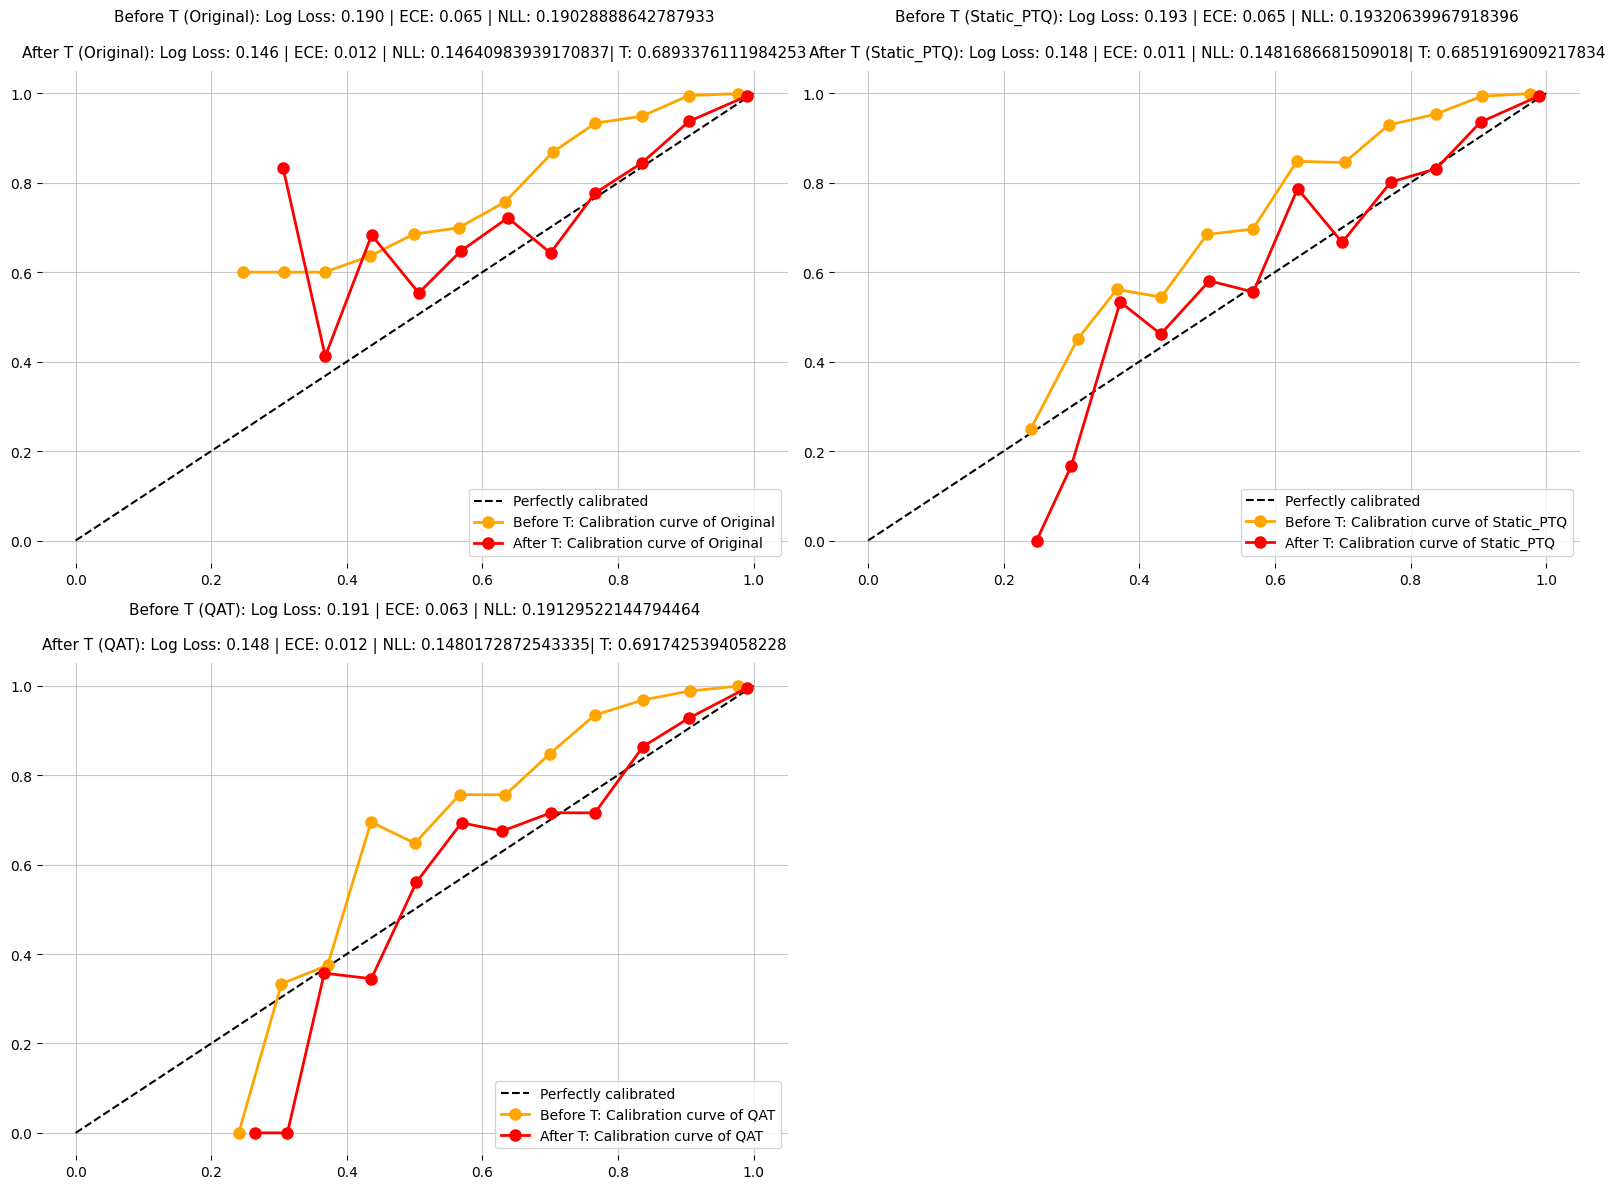

In [121]:
visualize_reliability_diagram(calibrated_result=calibrated_results,model_names=models_collection,row_expand=8,col_expand=6)

# AOTInductor Compiling method Part

In [159]:
compiled_static_loaded_model=torch_inductor(Static_PTQ.module().to("cpu"),128)
compiled_qat_loaded_model=torch_inductor(QAT_model.module().to("cpu"),128)
compiled_original_loaded_model=torch_inductor(original_model_.to("cpu"),128)

Exception ignored in: <function tqdm.__del__ at 0x790d8ab12e80>
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/tqdm/std.py", line 1148, in __del__
    self.close()
  File "/usr/local/lib/python3.12/dist-packages/tqdm/notebook.py", line 277, in close
    self.disp(bar_style='danger', check_delay=False)
    ^^^^^^^^^
AttributeError: 'tqdm' object has no attribute 'disp'


Compiling and tuning kernels... (This takes a moment)


skipping cudagraphs due to cpp wrapper enabled
/usr/local/lib/python3.12/dist-packages/torch/_inductor/mkldnn_lowerings.py:764: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.tensor(w_zp_tensor, dtype=torch.int32), name=w_zp.get_name()


Compilation successful!
Compiling and tuning kernels... (This takes a moment)


skipping cudagraphs due to cpp wrapper enabled
/usr/local/lib/python3.12/dist-packages/torch/_inductor/mkldnn_lowerings.py:764: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.tensor(w_zp_tensor, dtype=torch.int32), name=w_zp.get_name()


Compilation successful!
Compiling and tuning kernels... (This takes a moment)


skipping cudagraphs due to cpp wrapper enabled
Autotune Choices Stats:
{"num_choices": 2, "num_triton_choices": 0, "best_kernel": "_mkl_linear", "best_time": 0.04662999981519533}
AUTOTUNE packed_linear(128x512, 1982689x1, 10x512)
strides: [512, 1], [1, 0], [512, 1]
dtypes: torch.float32, torch.float32, torch.float32
  _mkl_linear 0.0466 ms 100.0% 
  cpp_CppMicroGemmFP32Vec_31 0.0931 ms 50.1% 
SingleProcess AUTOTUNE benchmarking takes 0.2565 seconds and 3.4535 seconds precompiling for 2 choices


Compilation successful!


In [133]:
import time 
start=time.perf_counter()
static_exp5_v3_history=test_model(
    model=compiled_static_loaded_model,
    test_dataloader=test_loader,
    num_classes=10,
    device=torch.device("cpu"),
    test_result_dir="./result/exp5_v3_last_static_test"
        )
end=time.perf_counter()
print(f"Elapsed time: {end-start:.6f} seconds")

print(f"Test acc: {static_exp5_v3_history["test_acc"]}")

test model is in progress:   0%|          | 0/79 [00:00<?, ?it/s]

skipping cudagraphs due to cpp wrapper enabled
/usr/local/lib/python3.12/dist-packages/torch/_inductor/mkldnn_lowerings.py:764: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.tensor(w_zp_tensor, dtype=torch.int32), name=w_zp.get_name()
skipping cudagraphs due to cpp wrapper enabled
/usr/local/lib/python3.12/dist-packages/torch/_inductor/mkldnn_lowerings.py:764: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.tensor(w_zp_tensor, dtype=torch.int32), name=w_zp.get_name()


Elapsed time: 136.618697 seconds
Test acc: 91.84


In [134]:
qat_exp5_v3_history=test_model(
    model=compiled_qat_loaded_model,
    test_dataloader=test_loader,
    num_classes=10,
    device=torch.device("cpu"),
    test_result_dir="./result/exp5_v3_last_qat_test"
        )

print(f"Test acc: {qat_exp5_v3_history["test_acc"]}")

test model is in progress:   0%|          | 0/79 [00:00<?, ?it/s]

skipping cudagraphs due to cpp wrapper enabled
/usr/local/lib/python3.12/dist-packages/torch/_inductor/mkldnn_lowerings.py:764: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.tensor(w_zp_tensor, dtype=torch.int32), name=w_zp.get_name()
skipping cudagraphs due to cpp wrapper enabled
/usr/local/lib/python3.12/dist-packages/torch/_inductor/mkldnn_lowerings.py:764: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.tensor(w_zp_tensor, dtype=torch.int32), name=w_zp.get_name()


Test acc: 92.52


In [160]:
qat_exp5_v3_history=test_model(
    model=compiled_original_loaded_model,
    test_dataloader=test_loader,
    num_classes=10,
    device=torch.device("cpu"),
    test_result_dir="./result/exp5_v3_original_test"
        )

print(f"Test acc: {qat_exp5_v3_history["test_acc"]}")

test model is in progress:   0%|          | 0/79 [00:00<?, ?it/s]

skipping cudagraphs due to cpp wrapper enabled
Autotune Choices Stats:
{"num_choices": 2, "num_triton_choices": 0, "best_kernel": "cpp_CppMicroGemmFP32Vec_32", "best_time": 0.015902999621175695}
AUTOTUNE linear_unary(16x512, 10x512, 10)
strides: [512, 1], [1, 0], [1]
dtypes: torch.float32, torch.float32, torch.float32
  cpp_CppMicroGemmFP32Vec_32 0.0159 ms 100.0% 
  _linear_pointwise 0.0674 ms 23.6% 
SingleProcess AUTOTUNE benchmarking takes 0.2517 seconds and 4.3292 seconds precompiling for 2 choices


Test acc: 94.31


In [165]:
results=measure_inference_mb_ms(model=compiled_original_loaded_model,input_shape=(1,3,224,224),save_path="../o",is_production=False,experiment_name="exp5_v3",device=torch.device("cpu"))
print(f"Exp 5 V 3.0 size and inference time (original): {results}")

skipping cudagraphs due to cpp wrapper enabled


Average latency: 18.997 ms
State dict size: 44.81 MB
Exp 5 V 3.0 size and inference time (original): {'model_time_ms': 18.99738001005062, 'state_dict_size_mb': 44.805451, 'exported_file_size_mb': None}


In [166]:
results=measure_inference_mb_ms(model=compiled_static_loaded_model,input_shape=(1,3,224,224),save_path="../o",is_production=False,experiment_name="exp5_v3",device=torch.device("cpu"))
print(f"Exp 5 V 3.0 size and inference time b (Static): {results}")

skipping cudagraphs due to cpp wrapper enabled
/usr/local/lib/python3.12/dist-packages/torch/_inductor/mkldnn_lowerings.py:764: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.tensor(w_zp_tensor, dtype=torch.int32), name=w_zp.get_name()


Average latency: 13.810 ms
State dict size: 11.28 MB
Exp 5 V 3.0 size and inference time b (Static): {'model_time_ms': 13.80987896996885, 'state_dict_size_mb': 11.276007, 'exported_file_size_mb': None}


In [167]:
results=measure_inference_mb_ms(model=compiled_qat_loaded_model,input_shape=(1,3,224,224),save_path="../o",is_production=False,experiment_name="exp5_v3",device=torch.device("cpu"))
print(f"Exp 5 V 3.0 size and inference time (QAT): {results}")

Average latency: 13.451 ms
State dict size: 11.28 MB
Exp 5 V 3.0 size and inference time (QAT): {'model_time_ms': 13.45137089997479, 'state_dict_size_mb': 11.276135, 'exported_file_size_mb': None}


## Compile with AOT Inductor for Inference, So No required to recompile model at the runtime

In [135]:
import os
import torch

def compile_models_with_aot_compiler(model,model_name,device=torch.device("cpu")):
    
    if isinstance(model, nn.Module):
        try:
            model.eval()
            model.to(device)
            model=export_model(model)
        except NotImplementedError: 
            torchao.quantization.pt2e.move_exported_model_to_eval(model)
            model.to(device)
    else:
        # AOTInductor models are already compiled for a specific device/mode.
        # Fall back gracefully if it exposes PyTorch 2.0 graph structures.
        if hasattr(model, "eval"):
            try:
                model.eval()
            except Exception:
                pass

        

    inductor_options = {
        "freezing": True,
        "cpp_wrapper": True
    }
        
    with torch.no_grad():
        output_path = torch._inductor.aoti_compile_and_package(
            model,   
            package_path=os.path.join(os.getcwd(), f"{model_name}_last_model.pt2"),
            inductor_configs=inductor_options  
        )
        
    return output_path


In [147]:

#Compile models 
qat_aot_model=compile_models_with_aot_compiler(QAT_model,"AOT_compiled_static")
static_aot_model=compile_models_with_aot_compiler(Static_PTQ,"AOT_compiled_QAT")
original_model=compile_models_with_aot_compiler(original_model_,"AOT_compiled_original")

/usr/local/lib/python3.12/dist-packages/torch/_inductor/mkldnn_lowerings.py:764: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.tensor(w_zp_tensor, dtype=torch.int32), name=w_zp.get_name()
/usr/local/lib/python3.12/dist-packages/torch/_inductor/mkldnn_lowerings.py:764: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.tensor(w_zp_tensor, dtype=torch.int32), name=w_zp.get_name()


In [148]:
import torch
import torch._inductor.codecache


print(torch.__version__)

print(hasattr(torch._inductor, "aoti_load_package"))
print(hasattr(torch._inductor, "codecache"))

2.10.0+cu128
True
True


In [149]:
#reload compiled static model 
static_aot_model = torch._inductor.aoti_load_package(static_aot_model)
qat_aot_model = torch._inductor.aoti_load_package(qat_aot_model)
original_aot_model = torch._inductor.aoti_load_package(original_model)



# Test acc of Compiled Quantized Static model, QAT and original Baseline candidate chosen from the experiments

In [153]:
start=time.perf_counter()
original_aot_history=test_model(
    model=original_aot_model,
    test_dataloader=test_loader,
    num_classes=10,
    device=torch.device("cpu"),
    test_result_dir="./result/AOT_Original"
        )

end=time.perf_counter()
print(f"Elapsed time (Original): {end-start:.6f} seconds")
print(f"Original Test acc: {original_aot_history["test_acc"]}")

test model is in progress:   0%|          | 0/79 [00:00<?, ?it/s]

Elapsed time (Original): 204.001199 seconds
Original Test acc: 94.31


In [154]:
start=time.perf_counter()
static_aot_compiled_history=test_model(
    model=static_aot_model,
    test_dataloader=test_loader,
    num_classes=10,
    device=torch.device("cpu"),
    test_result_dir="./result/Static_PTQ"
        )

end=time.perf_counter()
print(f"Elapsed time (Static PTQ): {end-start:.6f} seconds")
print(f"Test acc (Static PTQ): {static_aot_compiled_history["test_acc"]}")

test model is in progress:   0%|          | 0/79 [00:00<?, ?it/s]

Elapsed time (Static PTQ): 125.735951 seconds
Test acc (Static PTQ): 91.84


In [155]:
start=time.perf_counter()
QAT_aot_compiled_history=test_model(
    model=qat_aot_model,
    test_dataloader=test_loader,
    num_classes=10,
    device=torch.device("cpu"),
    test_result_dir="./result/QAT_test")

end=time.perf_counter()
print(f"Elapsed time (QAT): {end-start:.6f} seconds")
print(f"Test acc (QAT): {QAT_aot_compiled_history["test_acc"]}")

test model is in progress:   0%|          | 0/79 [00:00<?, ?it/s]

Elapsed time (QAT): 126.941695 seconds
Test acc (QAT): 92.52


In [168]:
results=measure_inference_mb_ms(model=original_aot_model,input_shape=(1,3,224,224),save_path="../o",is_production=False,experiment_name="exp5_v3",device=torch.device("cpu"))
print(f"Exp 5 V 3.0 size and inference time (original): {results}")

Average latency: 24.796 ms
State dict size: N/A (AOTCompiled Module)
Exp 5 V 3.0 size and inference time (original): {'model_time_ms': 24.796488929960105, 'state_dict_size_mb': None, 'exported_file_size_mb': None}


In [169]:
results=measure_inference_mb_ms(model=static_aot_model,input_shape=(1,3,224,224),save_path="../o",is_production=False,experiment_name="exp5_v3",device=torch.device("cpu"))
print(f"Exp 5 V 3.0 size and inference time (Static): {results}")

Average latency: 14.715 ms
State dict size: N/A (AOTCompiled Module)
Exp 5 V 3.0 size and inference time (Static): {'model_time_ms': 14.714850340023986, 'state_dict_size_mb': None, 'exported_file_size_mb': None}


In [170]:
results=measure_inference_mb_ms(model=qat_aot_model,input_shape=(1,3,224,224),save_path="../o",is_production=False,experiment_name="exp5_v3",device=torch.device("cpu"))
print(f"Exp 5 V 3.0 size and inference time before : {results}")

Average latency: 15.006 ms
State dict size: N/A (AOTCompiled Module)
Exp 5 V 3.0 size and inference time before : {'model_time_ms': 15.005551940012083, 'state_dict_size_mb': None, 'exported_file_size_mb': None}


## Test the Compiled model , (Note: AOT comipiled model in advance, So you don't need to compile at runtime as warmup as Just In Time method)

# Prediction test for QAT. Static.Original

In [25]:
from src.grad_cam import GradCAM,process_input_image

In [26]:
print(f"length of train dataset after splitting {len(train_dataset)}")
print(f"length of val dataset after splitting {len(val_dataset)}")
print(f"length of test dataset  {len(test_dataset)}")

#get the classes
cifar10_classes=train_dataset.subset.dataset.classes
cifar10_classes_len=len(cifar10_classes)
#num classes
print(cifar10_classes)
print(f"Len of classes {cifar10_classes_len}")

length of train dataset after splitting 40000
length of val dataset after splitting 10000
length of test dataset  10000
['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
Len of classes 10


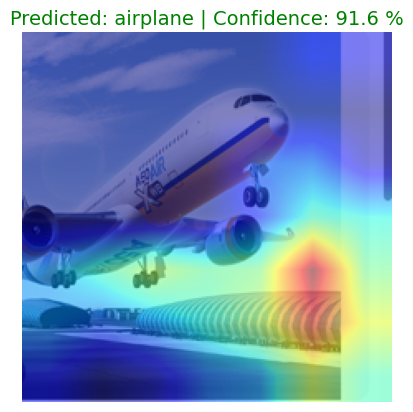

In [37]:
#get the last CNN layer of exp5_v3 for Grad Cam
last_conv2d=original_model_.layer4[-1]
#apply grad cam 
gradcam=GradCAM(original_model_,last_conv2d)
#visualize the Grad CAM 
pred_idx, pred_conf, top5_predictions,fig=process_input_image(
    image_path="/kaggle/input/datasets/zarniminnnyan/images/images",
    temperature_path=temperature_path,
    image_name="aeroplane.png",
    gradcam=gradcam,
    model=original_aot_model,
    classes=cifar10_classes,
    experiment_name="Original", #Be aware ( it should be the same folder name saved for temperature )
    device=device,
    add_temperature=True)

In [33]:
top5_predictions

{'airplane': 0.9164958000183105,
 'bird': 0.06469451636075974,
 'automobile': 0.004558010026812553,
 'ship': 0.004555189982056618,
 'cat': 0.004378797020763159}